## Task - 9
### Activity 1 – Import required libraries

In [36]:
# Import required libraries
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [37]:
# step 1: Load TED Talks dataset
talks = pd.read_csv(
    "../data/processed/ted_talks_cleaned.csv"
)

# Load user interaction dataset
interactions = pd.read_csv(
    "../data/interaction/user_interactions.csv"
)

print("TED Talks Dataset:", talks.shape)
print("User Interactions Dataset:", interactions.shape)

print("\nTED Talks Columns:")
print(talks.columns.tolist())

print("\nInteraction Data:")
display(interactions.head())

TED Talks Dataset: (4005, 24)
User Interactions Dataset: (32, 6)

TED Talks Columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'topics_clean', 'combined_text']

Interaction Data:


,user_id,talk_id,rating,liked,watched,saved
0,1,995,5,1,1,1
1,1,1307,4,1,1,0
2,1,1879,2,0,1,0
3,1,41223,5,1,1,1
4,2,995,5,1,1,0


In [38]:
# step2 : Prepare the datasets
# Standardize the TED Talk ID column
if "talk_id" not in talks.columns:
    talks = talks.rename(columns={"id": "talk_id"})

# Convert IDs to the same format
talks["talk_id"] = talks["talk_id"].astype(str)
interactions["talk_id"] = interactions["talk_id"].astype(str)

# Clean missing text values
for col in ["title", "description", "topics"]:
    if col not in talks.columns:
        talks[col] = ""
    talks[col] = talks[col].fillna("").astype(str)

# Create combined text features
talks["combined_features"] = (
    talks["title"] + " " +
    talks["description"] + " " +
    talks["topics"]
)

print("Dataset preparation completed!")
display(talks[["talk_id", "title", "combined_features"]].head())

Dataset preparation completed!


,talk_id,title,combined_features
0,1,Averting the climate crisis,Averting the climate crisis With the same humo...
1,92,The best stats you've ever seen,The best stats you've ever seen You've never s...
2,7,Simplicity sells,Simplicity sells New York Times columnist Davi...
3,53,Greening the ghetto,Greening the ghetto In an emotionally charged ...
4,66,Do schools kill creativity?,Do schools kill creativity? Sir Ken Robinson m...


### Activity 1 – Load the Content-Based Recommendation Model

In [39]:
# step 3: Generate content features
# Create TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(
    talks["combined_features"]
)

# Calculate talk-to-talk similarity
content_similarity = cosine_similarity(tfidf_matrix)

print("Content-Based Model Loaded Successfully!")
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Similarity Matrix Shape:", content_similarity.shape)

Content-Based Model Loaded Successfully!
TF-IDF Matrix Shape: (4005, 5000)
Similarity Matrix Shape: (4005, 4005)


### Activity 2 – Load the Collaborative Filtering Model

In [40]:
# step 4: Create user-item rating matrix
user_item_matrix = interactions.pivot_table(
    index="user_id",
    columns="talk_id",
    values="rating",
    aggfunc="mean"
).fillna(0)

print("User-Item Matrix:")
display(user_item_matrix)

# Calculate user similarity
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

print("\nUser Similarity Matrix:")
display(user_similarity_df)

User-Item Matrix:


talk_id,1075,1307,1776,1879,2338,2441,32269,41223,995
user_id,,,,,,,,,
1,0.0,4.0,0.0,2.0,0.0,0.0,0.0,5.0,5.0
2,0.0,4.0,0.0,2.0,0.0,0.0,5.0,0.0,5.0
3,0.0,0.0,0.0,5.0,0.0,5.0,4.0,2.0,0.0
4,0.0,0.0,0.0,5.0,0.0,5.0,4.0,0.0,2.0
5,0.0,5.0,4.0,0.0,0.0,0.0,0.0,3.0,4.0
6,0.0,2.0,5.0,5.0,0.0,4.0,0.0,0.0,0.0
7,5.0,0.0,2.0,0.0,0.0,0.0,0.0,4.0,5.0
8,3.0,0.0,0.0,4.0,5.0,0.0,5.0,0.0,0.0



User Similarity Matrix:


user_id,1,2,3,4,5,6,7,8
user_id,,,,,,,,
1,1.000000,0.642857,0.285714,0.285714,0.809174,0.257143,0.642857,0.110410
2,0.642857,1.000000,0.428571,0.571429,0.588490,0.257143,0.357143,0.455443
3,0.285714,0.428571,1.000000,0.942857,0.088273,0.642857,0.114286,0.552052
4,0.285714,0.571429,0.942857,1.000000,0.117698,0.642857,0.142857,0.552052
5,0.809174,0.588490,0.088273,0.117698,1.000000,0.441367,0.588490,0.000000
6,0.257143,0.257143,0.642857,0.642857,0.441367,1.000000,0.142857,0.276026
7,0.642857,0.357143,0.114286,0.142857,0.588490,0.142857,1.000000,0.207020
8,0.110410,0.455443,0.552052,0.552052,0.000000,0.276026,0.207020,1.000000


### Activity 3 – Generate recommendations from both models

In [41]:
# step 5 :Collaborative Filtering function
def collaborative_scores(user_id):

    if user_id not in user_item_matrix.index:
        raise ValueError("User not found!")

    user_index = list(user_item_matrix.index).index(user_id)

    similarities = user_similarity[user_index]

    ratings = user_item_matrix.values

    weighted_ratings = np.dot(similarities, ratings)

    total_similarity = np.dot(
        np.abs(similarities),
        (ratings > 0).astype(int)
    )

    scores = np.divide(
        weighted_ratings,
        total_similarity,
        out=np.zeros_like(weighted_ratings, dtype=float),
        where=total_similarity != 0
    )

    result = pd.Series(
        scores,
        index=user_item_matrix.columns
    )

    # Exclude already rated talks
    rated_talks = user_item_matrix.loc[user_id]
    result = result[rated_talks == 0]

    # Normalize ratings from 1-5 into 0-1
    return result.clip(0, 5) / 5


In [42]:
# Step 6: Content-Based function
def content_scores(user_id):

    user_data = interactions[
        interactions["user_id"] == user_id
    ].copy()

    if user_data.empty:
        raise ValueError("User not found!")

    # Identify positive user preferences
    positive = (
        (user_data["rating"] >= 4) |
        (user_data["liked"].astype(str).str.lower() == "true") |
        (user_data["saved"].astype(str).str.lower() == "true")
    )

    liked_talks = user_data[positive]

    if liked_talks.empty:
        liked_talks = user_data

    # Calculate weighted content similarity
    scores = np.zeros(len(talks))

    talk_indices = {
        talk_id: index
        for index, talk_id in enumerate(talks["talk_id"])
    }

    for _, row in liked_talks.iterrows():

        talk_id = row["talk_id"]

        if talk_id in talk_indices:

            index = talk_indices[talk_id]

            weight = max(float(row["rating"]), 1) / 5

            scores += content_similarity[index] * weight

    # Normalize content scores
    if scores.max() > 0:
        scores = scores / scores.max()

    result = pd.Series(
        scores,
        index=talks["talk_id"]
    )

    # Exclude talks already interacted with
    watched_talks = user_data["talk_id"].unique()

    result = result[
        ~result.index.isin(watched_talks)
    ]

    return result

In [43]:
# step 7 : Generate recommendations for User 1
selected_user = 1

content_result = content_scores(selected_user)
cf_result = collaborative_scores(selected_user)

print("Content-Based Recommendations:")

display(
    content_result.sort_values(
        ascending=False
    ).head(5).reset_index(
        name="Content Score"
    )
)

print("\nCollaborative Filtering Recommendations:")

display(
    cf_result.sort_values(
        ascending=False
    ).head(5).reset_index(
        name="Collaborative Score"
    )
)

Content-Based Recommendations:


,talk_id,Content Score
0,24076,0.553913
1,2285,0.467737
2,1148,0.425111
3,23735,0.393757
4,52017,0.352180



Collaborative Filtering Recommendations:


,talk_id,Collaborative Score
0,2338,1.000000
1,1075,0.941370
2,2441,0.937931
3,32269,0.913727
4,1776,0.679641


### Activity 4 – Combine scores using a weighted approach

In [44]:
# step 8 :Create the hybrid recommendation function
def hybrid_recommendations(user_id, top_n=5,
                           content_weight=0.5,
                           collaborative_weight=0.5):

    if not np.isclose(
        content_weight + collaborative_weight, 1.0
    ):
        raise ValueError("Weights must sum to 1.")

    # Get scores from both models
    content = content_scores(user_id)
    collaborative = collaborative_scores(user_id)

    # Combine both recommendation lists
    combined = pd.DataFrame({
        "talk_id": talks["talk_id"]
    })

    combined["Content Score"] = (
        combined["talk_id"].map(content).fillna(0)
    )

    combined["Collaborative Score"] = (
        combined["talk_id"].map(collaborative).fillna(0)
    )

    # Calculate weighted hybrid score
    combined["Hybrid Score"] = (
        content_weight * combined["Content Score"] +
        collaborative_weight * combined["Collaborative Score"]
    )

    # Remove previously interacted talks
    previous_talks = interactions[
        interactions["user_id"] == user_id
    ]["talk_id"].unique()

    combined = combined[
        ~combined["talk_id"].isin(previous_talks)
    ]

    # Remove duplicate talk IDs
    combined = combined.drop_duplicates(
        subset=["talk_id"]
    )

    # Add TED Talk titles
    combined = combined.merge(
        talks[["talk_id", "title"]].drop_duplicates(
            subset=["talk_id"]
        ),
        on="talk_id",
        how="left"
    )

    # Sort by hybrid score
    combined = combined.sort_values(
        by="Hybrid Score",
        ascending=False
    )

    return combined[
        ["talk_id", "title", "Content Score",
         "Collaborative Score", "Hybrid Score"]
    ].head(top_n).reset_index(drop=True)

### Activity 5 – Remove duplicate recommendations
we have already implemented duplicate removal inside the hybrid function

### Activity 6 – Rank the combined recommendations
Ranking is also implemented inside the hybrid function

### Activity 7 – Test the hybrid model

In [45]:
# step 9 :Test with User 1
selected_user = 1

hybrid_result = hybrid_recommendations(
    selected_user,
    top_n=5
)

print("Hybrid Recommendations for User", selected_user)

display(hybrid_result)

Hybrid Recommendations for User 1


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.168804,1.000000,0.584402
1,1075,The linguistic genius of babies,0.043326,0.941370,0.492348
2,2441,The case for optimism on climate change,0.020128,0.937931,0.479029
3,32269,The uncomplicated truth about women's sexuality,0.034022,0.913727,0.473874
4,1776,Anatomy of a New Yorker cartoon,0.022090,0.679641,0.350866


In [46]:
# step 10 : Test with multiple users
for user_id in interactions["user_id"].unique():

    print("\nUser ID:", user_id)

    result = hybrid_recommendations(
        user_id,
        top_n=5
    )

    display(result)


User ID: 1


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.168804,1.000000,0.584402
1,1075,The linguistic genius of babies,0.043326,0.941370,0.492348
2,2441,The case for optimism on climate change,0.020128,0.937931,0.479029
3,32269,The uncomplicated truth about women's sexuality,0.034022,0.913727,0.473874
4,1776,Anatomy of a New Yorker cartoon,0.022090,0.679641,0.350866



User ID: 2


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.088897,1.000000,0.544449
1,2441,The case for optimism on climate change,0.006884,0.959091,0.482987
2,1075,The linguistic genius of babies,0.040510,0.775806,0.408158
3,41223,The mysterious science of pain,0.073223,0.720401,0.396812
4,1776,Anatomy of a New Yorker cartoon,0.025860,0.723985,0.374923



User ID: 3


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.119723,1.000000,0.559862
1,1776,Anatomy of a New Yorker cartoon,0.005597,0.898008,0.451802
2,1075,The linguistic genius of babies,0.120919,0.668605,0.394762
3,995,Glorious visions in animation and performance,0.000000,0.686311,0.343155
4,1307,Medicine for the 99 percent,0.005106,0.634312,0.319709


... (6 outputs left out)


User ID: 7


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.164146,1.000000,0.582073
1,32269,The uncomplicated truth about women's sexuality,0.046436,0.937382,0.491909
2,2441,The case for optimism on climate change,0.020691,0.928571,0.474631
3,1307,Medicine for the 99 percent,0.034213,0.834976,0.434595
4,1879,What is so special about the human brain?,0.148980,0.600874,0.374927



User ID: 8


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2441,The case for optimism on climate change,0.034883,0.960000,0.497441
1,41223,The mysterious science of pain,0.195843,0.571429,0.383636
2,995,Glorious visions in animation and performance,0.014742,0.750000,0.382371
3,1776,Anatomy of a New Yorker cartoon,0.005240,0.742857,0.374049
4,1307,Medicine for the 99 percent,0.029422,0.668852,0.349137


In [47]:
# step 11: Compare all three recommendation models
user_id = 1

content_top = content_scores(user_id).sort_values(
    ascending=False
).head(5)

cf_top = collaborative_scores(user_id).sort_values(
    ascending=False
).head(5)

hybrid_top = hybrid_recommendations(
    user_id,
    top_n=5
)

print("CONTENT-BASED RECOMMENDATIONS")
display(
    content_top.rename("Score").reset_index()
)

print("COLLABORATIVE FILTERING RECOMMENDATIONS")
display(
    cf_top.rename("Score").reset_index()
)

print("HYBRID RECOMMENDATIONS")
display(hybrid_top)

CONTENT-BASED RECOMMENDATIONS


,talk_id,Score
0,24076,0.553913
1,2285,0.467737
2,1148,0.425111
3,23735,0.393757
4,52017,0.352180


COLLABORATIVE FILTERING RECOMMENDATIONS


,talk_id,Score
0,2338,1.000000
1,1075,0.941370
2,2441,0.937931
3,32269,0.913727
4,1776,0.679641


HYBRID RECOMMENDATIONS


,talk_id,title,Content Score,Collaborative Score,Hybrid Score
0,2338,How my mind came back to life — and no one knew,0.168804,1.000000,0.584402
1,1075,The linguistic genius of babies,0.043326,0.941370,0.492348
2,2441,The case for optimism on climate change,0.020128,0.937931,0.479029
3,32269,The uncomplicated truth about women's sexuality,0.034022,0.913727,0.473874
4,1776,Anatomy of a New Yorker cartoon,0.022090,0.679641,0.350866


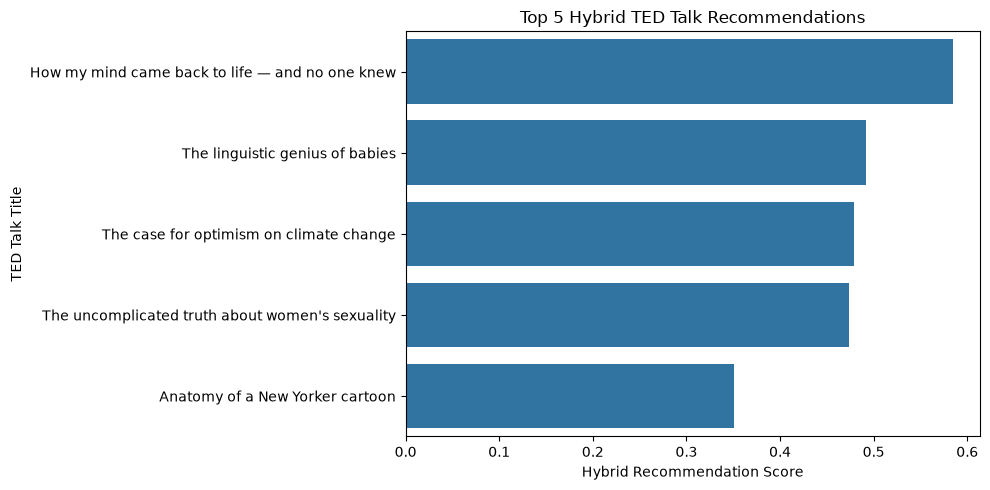

In [51]:
# step 12 : Visualize the hybrid recommendations, Add a bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=hybrid_result,
    x="Hybrid Score",
    y="title"
)

plt.title("Top 5 Hybrid TED Talk Recommendations")
plt.xlabel("Hybrid Recommendation Score")
plt.ylabel("TED Talk Title")

plt.tight_layout()
plt.show()

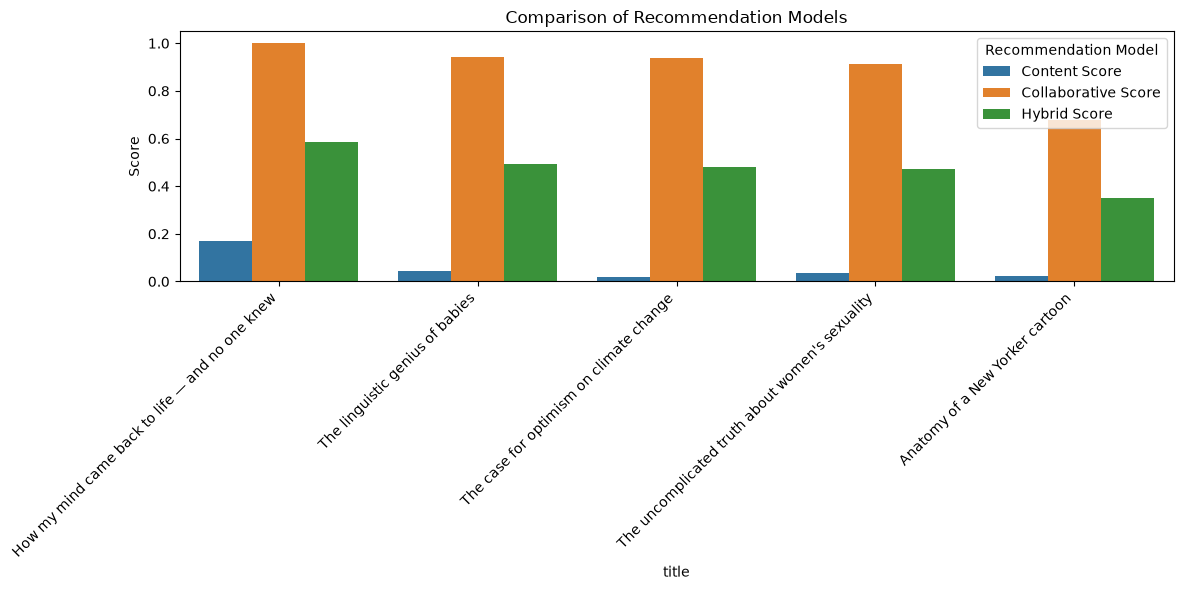

In [49]:
# step 13: Compare individual scores with hybrid scores, Add another visualization
comparison = hybrid_recommendations(
    user_id=1,
    top_n=5
)

comparison_plot = comparison.melt(
    id_vars="title",
    value_vars=[
        "Content Score",
        "Collaborative Score",
        "Hybrid Score"
    ],
    var_name="Recommendation Model",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="title",
    y="Score",
    hue="Recommendation Model"
)

plt.title("Comparison of Recommendation Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [50]:
# step 14: Save the final hybrid recommendations
hybrid_result = hybrid_recommendations(
    user_id=1,
    top_n=5
)

hybrid_result.to_csv(
    "../data/processed/task9_hybrid_recommendations.csv",
    index=False
)

print("Hybrid recommendations saved successfully!")

Hybrid recommendations saved successfully!


# Task 9 – Observations

1. The content-based recommendation model recommends TED Talks based on similarities in titles, descriptions, and topics.

2. The collaborative filtering model recommends TED Talks based on user ratings and similarities between users.

3. Both recommendation models were successfully combined using a weighted scoring approach.

4. A 50% weight was assigned to content-based filtering and 50% to collaborative filtering.

5. Duplicate recommendations were removed using unique TED Talk IDs.

6. The combined recommendations were ranked according to their hybrid scores.

7. The hybrid recommendation model was tested with different users.

8. The hybrid model combines content similarity and user preferences to provide personalized recommendations.

**Conclusion:**

The hybrid recommendation system successfully combines content-based and collaborative filtering techniques to generate personalized TED Talk recommendations. It uses both TED Talk features and user preferences to improve the recommendation process.